# CLASSIFICAÇÃO - ESCOLA PRIVADA NO ENSINO MÉDIO

Nesse notebook usamos a base `PARTICIPANTES_2025.csv` do ENEM 2025 para tentar prever se o aluno **pagou escola privada no ensino médio**, usando as respostas do questionário socioeconômico (renda, escolaridade dos pais, bens da casa etc).

Variável alvo, a partir da `Q023` ("Em que tipo de escola você frequentou o Ensino Médio?"):
- **1** se respondeu B ou D (estudou em escola privada sem bolsa integral, todo ou parte do EM)
- **0** se respondeu A, C ou E (só escola pública, ou privada com bolsa integral)
- quem respondeu F (não frequentou o EM) foi tirado

A base tem quase 5 milhões de linhas, então a gente sorteia só **5000 participantes** e trabalha com essa amostra.

Etapas:
0. leitura dos dados (amostra e treino/teste)
1. análise exploratória
2. pré-processamento
3. comparação de modelos
4. validação
5. avaliação final
6. interpretação dos resultados

In [16]:
import csv
from importlib.metadata import version
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from machinelearning_mnpkllps.Classification import KNN, Logistic_Regression, LDA
from machinelearning_mnpkllps.decision_tree import DecisionTreeClassification
from machinelearning_mnpkllps.Reamostragem import KFold
from machinelearning_mnpkllps.preprocessing import StandardScaler, train_test_split

# obs: usamos a versão 0.2.35 porque da 0.2.36 em diante o Classification.py tem um erro de sintaxe no KNN
print("versão da biblioteca:", version("machinelearning-mnpkllps"))

CSV = Path("PARTICIPANTES_2025.csv")
N_SAMPLE = 5000   # tamanho da amostra
TEST_SIZE = 0.2   # 20% pro teste
SEED = 20251      # mesma semente da regressão
K = 5             # numero de folds

# cores dos gráficos
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

versão da biblioteca: 0.2.35


## 0. Leitura dos dados: amostra e divisão treino/teste

Não dá pra carregar o arquivo todo, então lemos linha por linha e vamos sorteando (reservoir sampling, igual na regressão). No final, cada participante teve a mesma chance de cair na amostra. Depois separamos 80% treino e 20% teste com o `train_test_split` da biblioteca.

O teste só vai ser usado lá no final (etapa 5).

In [ ]:
COLUNAS = ["TP_FAIXA_ETARIA", "TP_SEXO", "TP_COR_RACA", "SG_UF_PROVA",
           "Q001", "Q002", "Q003", "Q004", "Q005", "Q006", "Q007", "Q008", "Q009", "Q010", "Q011",
           "Q012", "Q013", "Q014", "Q015", "Q016", "Q017", "Q018", "Q019", "Q020", "Q021", "Q022", "Q023"]

rng = np.random.default_rng(SEED)
amostra, elegiveis = [], 0
with open(CSV, encoding="latin-1", newline="") as f:  # o csv do inep vem em latin-1
    leitor = csv.reader(f, delimiter=";")
    pos = {nome: i for i, nome in enumerate(next(leitor))}
    idx = [pos[c] for c in COLUNAS]
    for linha in leitor:
        if linha[pos["Q023"]] == "F":   # não fez ensino medio, tira
            continue
        elegiveis += 1
        linha = [linha[i] for i in idx]
        if len(amostra) < N_SAMPLE:
            amostra.append(linha)
        else:
            # troca alguém da amostra com probabilidade N_SAMPLE/elegiveis
            j = rng.integers(elegiveis)
            if j < N_SAMPLE:
                amostra[j] = linha

dados = np.array(amostra, dtype=object)

col = {c: i for i, c in enumerate(COLUNAS)}

y_todos = np.isin(dados[:, col["Q023"]], ["B", "D"]).astype(int)   # alvo

D_tr, D_te, ytr, yte = train_test_split(dados, y_todos, test_size=TEST_SIZE, seed=SEED)


print(f"elegíveis na base: {elegiveis}, amostra: {len(dados)}")
print(f"treino: {len(D_tr)} ({ytr.mean():.1%} classe 1) | teste: {len(D_te)} ({yte.mean():.1%} classe 1)")

elegíveis na base: 4790277, amostra: 5000
treino: 4000 (17.2% classe 1) | teste: 1000 (17.0% classe 1)


## 1. Análise exploratória

Feita só com o treino. Primeiro vemos quantos de cada classe tem.

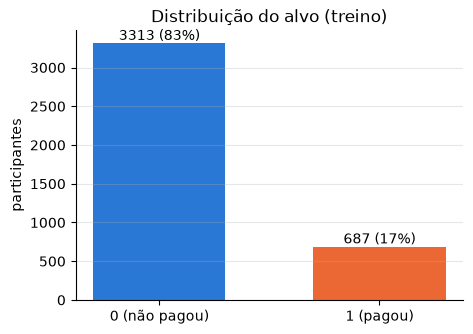

In [ ]:
cont = np.bincount(ytr)

plt.figure(figsize=(5, 3.5))
plt.bar(["0 (não pagou)", "1 (pagou)"], cont, color=[AZUL, LARANJA], width=0.6)
for i, c in enumerate(cont):
    plt.text(i, c, f"{c} ({c / len(ytr):.0%})", ha="center", va="bottom")
plt.title("Distribuição do alvo (treino)")
plt.ylabel("participantes")
plt.grid(axis="x")
plt.show()

As classes estão bem desbalanceadas, só uns 17% são classe 1. Um modelo que chuta sempre 0 já acerta 83%, então só a acurácia não serve pra comparar. Por isso usamos a **acurácia balanceada**, que é a média do acerto de cada classe (0.5 = chute). Também olhamos precisão, recall e F1 da classe 1.